# EfficientSAM on COCO 2017: Exploratory Data Analysis and Preprocessing Pipeline

**Paper:** *EfficientSAM: Leveraged Masked Image Pretraining for Efficient Segment Anything* (Xiong et al., CVPR 2024)
**Team:** Abrar Jameel Khatri (36241), Muhammad Taqi Salehi (36235), Syed Muhammad Mehdi Naqvi (36219)

This notebook is the code behind **Section 6 (EDA)** of our report *EfficientSAM_LitReview_EDA_v2*, followed by the **data loading and preprocessing pipeline** that the EDA leads to. Every number, table and figure in Section 6 is recomputed here from the real files.

| Part | Report section | Content |
|---|---|---|
| **A. EDA** | 6.1 | Dataset and scope, **Table 2** |
| | 6.2 | Class distribution and imbalance, **Figs. 1–2** |
| | 6.3 | Object scale and scene density, **Figs. 3–4** |
| | 6.4 | Image properties and the model's input pipeline |
| | 6.5 | Missing data and anomalies, **Figs. 5–8** |
| | 6.6 | Challenges specific to promptable segmentation, **Fig. 9** |
| | 6.7 | Evaluation metrics (IoU, Dice, pixel accuracy, Boundary IoU, COCO AP) |
| **B. Preprocessing** | 6.8 | Rules 1–6 → `Dataset` / `DataLoader` → check against the released EfficientSAM-Ti model |

### How to run (same setup as `TEAM_SETUP.md`)
Put this notebook in the `notebooks/` folder of our EfficientSAM repo (Part B needs `efficient_sam/` and `weights/`), then in PowerShell from the repo folder:
```powershell
.\.venv\Scripts\python.exe -m pip install -r requirements-eda.txt
.\.venv\Scripts\python.exe -m pip install torch torchvision scipy jupyter
$env:COCO_DATA_ROOT = "C:\Users\Abrar\Desktop\abrar\iba\ML\project\COCO_dataset"
.\.venv\Scripts\python.exe -m jupyter notebook          # open this notebook -> Run All (about 6-8 min on CPU)
```
The dataset folder must contain `annotations/` (the two subset files **and** the full `instances_train2017.json` / `instances_val2017.json`, used only for the full-COCO comparison) and `images/train2017`, `images/val2017`.

In [1]:
# =====================================================================================
# 0. Setup: imports, paths, constants
# =====================================================================================
import os, sys, re, json, time, random, hashlib
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage                       # connected components + distance transform
from pycocotools.coco import COCO               # official COCO API: reads the annotation files
from pycocotools import mask as mask_utils      # official COCO API: polygons/RLE -> binary masks
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
%matplotlib inline

# Same seed family as scripts/select_coco_subset.py, so every run gives identical results.
random.seed(36219); np.random.seed(36219); torch.manual_seed(36219)

# Dataset location: COCO_DATA_ROOT, exactly as in TEAM_SETUP.md (fallback = Abrar's folder).
DATA_ROOT = Path(os.environ.get("COCO_DATA_ROOT", r"C:\Users\Abrar\Desktop\abrar\iba\ML\project\COCO_dataset"))
ANN = DATA_ROOT / "annotations"
SPLITS = {   # split -> (subset annotation file, image folder)
    "train": (ANN / "subset_instances_train2017.json", DATA_ROOT / "images" / "train2017"),
    "eval":  (ANN / "subset_instances_val2017.json",   DATA_ROOT / "images" / "val2017"),
}
FULL_FILES = {"train": ANN / "instances_train2017.json", "eval": ANN / "instances_val2017.json"}
assert DATA_ROOT.exists(), f"Dataset not found at {DATA_ROOT}: set COCO_DATA_ROOT"
print("DATA_ROOT:", DATA_ROOT)

# Constants taken from the official EfficientSAM code (efficient_sam/efficient_sam.py).
MODEL_SIZE = 1024                                   # image_encoder.img_size
PATCH = 16                                          # encoder_patch_size -> 64 x 64 tokens
PIXEL_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)   # ImageNet mean
PIXEL_STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)   # ImageNet std

# One plotting style for all figures (blue = train, orange = eval, as in the report).
C_TRAIN, C_EVAL, C_3, INK2 = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "font.size": 8, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True, "legend.frameon": False,
                     "axes.titlesize": 9, "axes.titleweight": "bold"})

DATA_ROOT: /tmp/claude-0/-home-claude/45691986-9396-580e-ba08-03920c1c29ef/scratchpad/data/COCO2017_subset


---
# Part A: Exploratory Data Analysis (report Section 6)

## 6.1 Dataset and scope
We use the fixed COCO 2017 subset made by `scripts/select_coco_subset.py`: **800** `train2017` images (seed 36219) and **200** `val2017` images (seed 36220). Each image keeps all its annotations, crowd entries included. The 800 are our development split and the 200 are held out.

The cell below loads the two subset files and builds one table (`INST`) with one row per annotation, holding everything the EDA needs. Masks are decoded **once** with the COCO API (merging the polygons of an object with a union, so overlapping parts count once).

In [2]:
# ---------------------------------------------------------------
# 6.1a Load the subset annotation files with the official COCO API
# ---------------------------------------------------------------
cocos = {s: COCO(str(f)) for s, (f, _) in SPLITS.items()}
CATS = cocos["train"].cats                                   # 80 category definitions (same in both files)
CAT_NAME  = {k: v["name"] for k, v in CATS.items()}
CAT_SUPER = {k: v["supercategory"] for k, v in CATS.items()}

def decode(ann, h, w):
    # COCO segmentation (polygons or RLE) -> H x W boolean mask.
    seg = ann["segmentation"]
    if isinstance(seg, list):                                # polygons: merge = UNION (overlap counted once)
        rle = mask_utils.merge(mask_utils.frPyObjects(seg, h, w))
    elif isinstance(seg["counts"], list):                    # uncompressed RLE (crowd entries)
        rle = mask_utils.frPyObjects(seg, h, w)
    else:                                                    # compressed RLE
        rle = seg
    return mask_utils.decode(rle).astype(bool)

# ---------------------------------------------------------------
# 6.1b One row per annotation with every statistic used in Section 6
# ---------------------------------------------------------------
t0 = time.time()
INST = {}
for split, coco in cocos.items():
    rows = defaultdict(list)
    for ann in coco.dataset["annotations"]:
        info = coco.imgs[ann["image_id"]]; H, W = info["height"], info["width"]
        m = decode(ann, H, W)
        px = int(m.sum())                                    # decoded (true) area in pixels
        x, y, w, h = ann["bbox"]
        cx, cy = int(min(W - 1, x + w / 2)), int(min(H - 1, y + h / 2))   # box centre pixel
        rows["ann_id"].append(ann["id"]); rows["img"].append(ann["image_id"])
        rows["cat"].append(CAT_NAME[ann["category_id"]]); rows["crowd"].append(ann["iscrowd"])
        rows["stored_area"].append(ann["area"]); rows["area_px"].append(px)
        rows["coverage"].append(100 * px / (H * W))          # % of the image covered
        rows["box_fill"].append(px / max(w * h, 1))          # mask area / box area
        rows["centre_in"].append(bool(m[cy, cx]) if px else False)
        rows["n_parts"].append(int(ndimage.label(m)[1]))     # connected components
        rows["min_side_1024"].append(min(w * MODEL_SIZE / W, h * MODEL_SIZE / H))   # after the 1024 resize
        rows["bbox_w"].append(w); rows["bbox_h"].append(h)
    INST[split] = {k: np.array(v) for k, v in rows.items()}
print(f"decoded {sum(len(v['ann_id']) for v in INST.values())} masks in {time.time()-t0:.0f}s; "
      f"empty masks: {sum(int((v['area_px'] == 0).sum()) for v in INST.values())}")

loading annotations into memory...
Done (t=0.06s)
creating index...
index created!
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!


decoded 7558 masks in 11s; empty masks: 0


In [3]:
# ---------------------------------------------------------------
# 6.1c Full COCO 2017 reference statistics (for Table 2 and Figs. 1b, 2b, 3b)
# ---------------------------------------------------------------
# The full train file is 449 MB. json.load() on it can need several GB of RAM, too much for our 8 GB
# laptops, so we STREAM it: read 16 MB at a time and pick out only the fields we need with a regex.
# (Each COCO annotation has the fixed key order area, iscrowd, image_id, bbox, category_id.)
ANN_RE = re.compile(rb'"area":\s*([0-9.eE+-]+),\s*"iscrowd":\s*(\d),\s*"image_id":\s*(\d+),'
                    rb'\s*"bbox":\s*\[[^\]]*\],\s*"category_id":\s*(\d+)')

def stream_full_stats(path):
    n_img, n_ann, crowd, imgs_with, cat_counts, sizes = 0, 0, 0, set(), Counter(), Counter()
    buf, tail = b"", b""
    with open(path, "rb") as f:
        while True:
            chunk = f.read(1 << 24)
            n_img += (tail + chunk).count(b'"coco_url"') - tail.count(b'"coco_url"'); tail = chunk[-20:]
            buf += chunk; last = 0
            for m in ANN_RE.finditer(buf):
                area = float(m.group(1)); n_ann += 1; crowd += int(m.group(2))
                imgs_with.add(int(m.group(3))); cat_counts[CAT_NAME[int(m.group(4))]] += 1
                sizes["small" if area < 32**2 else "medium" if area < 96**2 else "large"] += 1
                last = m.end()
            if not chunk: break
            buf = buf[max(last, len(buf) - 100_000):]          # keep an unfinished record for the next chunk
    return dict(images=n_img, annotations=n_ann, crowd=crowd, no_ann=n_img - len(imgs_with),
                cats=cat_counts, sizes=sizes)

t0 = time.time()
FULL = {s: stream_full_stats(p) for s, p in FULL_FILES.items()}
for s, v in FULL.items():
    print(f"full {s}: images={v['images']:,} annotations={v['annotations']:,} crowd={v['crowd']:,} "
          f"no-annotation images={v['no_ann']:,}")
print(f"({time.time()-t0:.0f}s)")

full train: images=118,287 annotations=860,001 crowd=10,052 no-annotation images=1,021
full eval: images=5,000 annotations=36,781 crowd=446 no-annotation images=48
(2s)


In [4]:
# ---------------------------------------------------------------
# 6.1d Table 2: dataset statistics (subset vs full COCO)
# ---------------------------------------------------------------
def size_split_stored(areas):
    # COCO size buckets on the STORED area (the way COCO itself defines them), all annotations.
    a = np.asarray(areas, float)
    v = np.array([(a < 32**2).sum(), ((a >= 32**2) & (a < 96**2)).sum(), (a >= 96**2).sum()])
    return 100 * v / v.sum()

TAB = {}
for s in SPLITS:
    coco, r = cocos[s], INST[s]
    per_img = Counter(r["img"]); counts = [per_img.get(i, 0) for i in coco.imgs]
    W = [i["width"] for i in coco.imgs.values()]; H = [i["height"] for i in coco.imgs.values()]
    TAB[s] = {
        "Images": f"{len(coco.imgs):,}",
        "Annotation entries": f"{len(r['ann_id']):,}",
        "   non-crowd / crowd": f"{int((r['crowd']==0).sum()):,} / {int(r['crowd'].sum())}",
        "Images with no annotation": f"{sum(c == 0 for c in counts)} ({100*sum(c == 0 for c in counts)/len(counts):.2f}%)",
        "Categories present (of 80)": f"{len(set(r['cat']))}",
        "Annotations/image: mean / median / max": f"{np.mean(counts):.1f} / {np.median(counts):.0f} / {max(counts)}",
        "Size: small / medium / large (%)": " / ".join(f"{v:.1f}" for v in size_split_stored(r["stored_area"])),
        "Width / height range (px)": f"{min(W)}–{max(W)} / {min(H)}–{max(H)}",
    }
for s in SPLITS:
    f = FULL[s]; sz = np.array([f["sizes"]["small"], f["sizes"]["medium"], f["sizes"]["large"]])
    TAB["full " + s] = {
        "Images": f"{f['images']:,}", "Annotation entries": f"{f['annotations']:,}",
        "   non-crowd / crowd": f"{f['annotations']-f['crowd']:,} / {f['crowd']:,}",
        "Images with no annotation": f"{f['no_ann']:,} ({100*f['no_ann']/f['images']:.2f}%)",
        "Categories present (of 80)": f"{len(f['cats'])}",
        "Annotations/image: mean / median / max": "–",
        "Size: small / medium / large (%)": " / ".join(f"{v:.1f}" for v in 100 * sz / sz.sum()),
        "Width / height range (px)": "–",
    }
cols = [("train", "Subset train"), ("eval", "Subset eval"), ("full train", "Full train2017"), ("full eval", "Full val2017")]
print("Table 2. Dataset statistics\n")
print(f"{'':40s}" + "".join(f"{n:>22s}" for _, n in cols))
for row in TAB["train"]:
    print(f"{row:40s}" + "".join(f"{TAB[k][row]:>22s}" for k, _ in cols))

Table 2. Dataset statistics

                                                  Subset train           Subset eval        Full train2017          Full val2017
Images                                                     800                   200               118,287                 5,000
Annotation entries                                       5,916                 1,642               860,001                36,781
   non-crowd / crowd                                5,843 / 73            1,620 / 22      849,949 / 10,052          36,335 / 446
Images with no annotation                            7 (0.88%)             1 (0.50%)         1,021 (0.86%)            48 (0.96%)
Categories present (of 80)                                  79                    76                    80                    80
Annotations/image: mean / median / max            7.4 / 4 / 55          8.2 / 5 / 63                     –                     –
Size: small / medium / large (%)            41.3 / 34.2 / 24.5    40

## 6.2 Class distribution and imbalance
EfficientSAM is class-agnostic (a prompt → a mask; labels never enter its loss), so imbalance does not bias the model. It does bias any **instance-averaged score**, which is why Section 6.7 stratifies the metrics by category.

In [5]:
# ---------------------------------------------------------------
# 6.2a Category counts, imbalance and subset-vs-full shares
# ---------------------------------------------------------------
ALL80 = [CAT_NAME[k] for k in sorted(CATS)]
cnt = {s: Counter(INST[s]["cat"]) for s in SPLITS}
tc, ec = cnt["train"], cnt["eval"]
n_train = len(INST["train"]["cat"])
order = sorted(ALL80, key=lambda k: -tc[k])

person_imgs = len(set(INST["train"]["img"][INST["train"]["cat"] == "person"]))
print(f"person: {tc['person']:,} train annotations ({100*tc['person']/n_train:.2f}%) in {person_imgs} of 800 images")
print("next:", ", ".join(f"{k} {tc[k]}" for k in order[1:3]))
print(f"top-5 categories hold {100*sum(tc[k] for k in order[:5])/n_train:.1f}% of training annotations")
print("rarest in train:", ", ".join(f"{k} {tc[k]}" for k in order[-4:][::-1]))
print(f"toothbrush: {tc['toothbrush']} train vs {ec['toothbrush']} eval  <- evaluated but never seen in development")
print("categories with 0 eval annotations:", [k for k in ALL80 if ec[k] == 0])
eval_imgs_per_cat = {k: len(set(INST['eval']['img'][INST['eval']['cat'] == k])) for k in ALL80}
print(f"eval categories present in fewer than 5 images: {sum(1 for k in ALL80 if eval_imgs_per_cat[k] < 5)}")

full = FULL["train"]["cats"]; n_full = FULL["train"]["annotations"]
for k in ["person", "car", "chair"]:
    print(f"share {k:6s}: full {100*full[k]/n_full:.2f}%  vs subset {100*tc[k]/n_train:.2f}%  "
          f"(diff {100*tc[k]/n_train - 100*full[k]/n_full:+.2f} points)")
xs = np.array([100 * full[k] / n_full for k in order]); ys = np.array([100 * tc[k] / n_train for k in order])
ok = ys > 0
r_log = np.corrcoef(np.log(xs[ok]), np.log(ys[ok]))[0, 1]
print(f"log-share correlation over categories present in train: r = {r_log:.2f}")

person: 1,869 train annotations (31.59%) in 456 of 800 images
next: car 313, chair 252
top-5 categories hold 46.8% of training annotations
rarest in train: toothbrush 0, toaster 1, hair drier 3, microwave 3
toothbrush: 0 train vs 5 eval  <- evaluated but never seen in development
categories with 0 eval annotations: ['fire hydrant', 'bear', 'snowboard', 'toaster']
eval categories present in fewer than 5 images: 37
share person: full 30.52%  vs subset 31.59%  (diff +1.07 points)
share car   : full 5.10%  vs subset 5.29%  (diff +0.19 points)
share chair : full 4.48%  vs subset 4.26%  (diff -0.22 points)
log-share correlation over categories present in train: r = 0.91


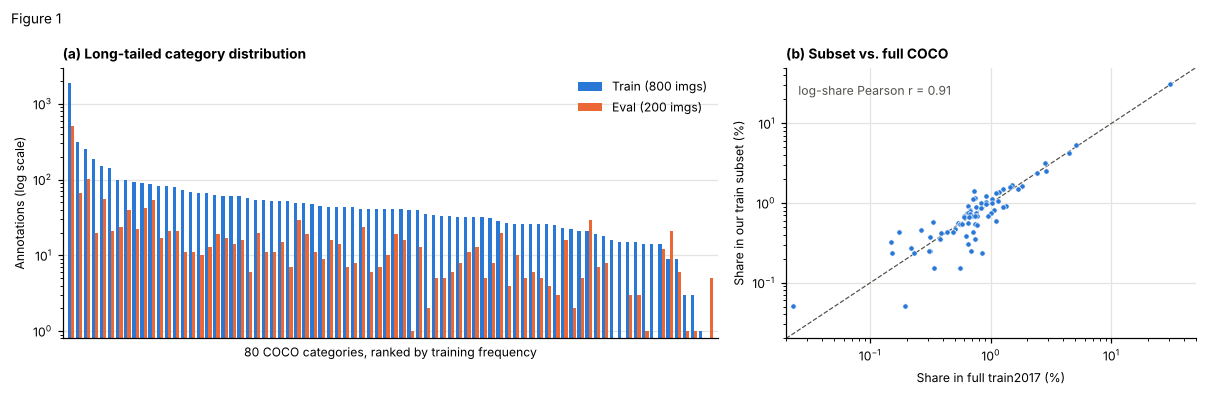

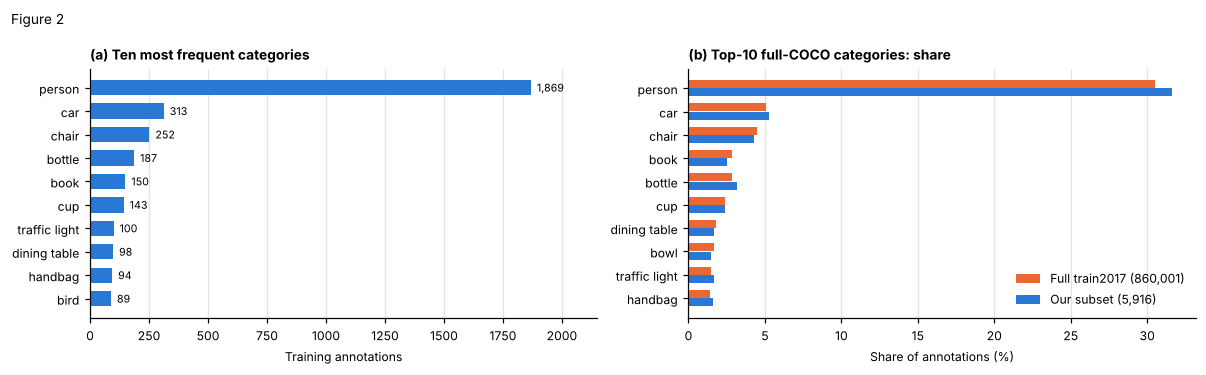

In [6]:
# ---------------------------------------------------------------
# Figure 1: (a) all 80 categories, train + eval, log scale; (b) subset share vs full share
# ---------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.6, 1]})
x = np.arange(80)
ax[0].bar(x - 0.2, [tc[k] for k in order], 0.4, color=C_TRAIN, label="Train (800 imgs)")
ax[0].bar(x + 0.2, [ec[k] for k in order], 0.4, color=C_EVAL, label="Eval (200 imgs)")
ax[0].set_yscale("log"); ax[0].set_ylim(0.8, 3000); ax[0].set_xlim(-1, 80); ax[0].set_xticks([])
ax[0].set_xlabel("80 COCO categories, ranked by training frequency"); ax[0].set_ylabel("Annotations (log scale)")
ax[0].legend(loc="upper right"); ax[0].set_title("(a) Long-tailed category distribution", loc="left")
ax[1].scatter(xs[ok], ys[ok], s=12, color=C_TRAIN, edgecolor="white", linewidth=0.4, zorder=3)
ax[1].plot([0.02, 50], [0.02, 50], "--", color=INK2, lw=0.8)
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlim(0.02, 50); ax[1].set_ylim(0.02, 50)
ax[1].set_xlabel("Share in full train2017 (%)"); ax[1].set_ylabel("Share in our train subset (%)")
ax[1].text(0.03, 0.9, f"log-share Pearson r = {r_log:.2f}", transform=ax[1].transAxes, color=INK2)
ax[1].set_title("(b) Subset vs. full COCO", loc="left")
fig.suptitle("Figure 1", x=0.01, ha="left", fontsize=9); plt.tight_layout(); plt.show()

# ---------------------------------------------------------------
# Figure 2: (a) ten most frequent training categories; (b) shares of the ten most frequent FULL-COCO categories
# ---------------------------------------------------------------
top_sub = order[:10]; top_full = sorted(ALL80, key=lambda k: -full[k])[:10]; yy = np.arange(10)[::-1]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].barh(yy, [tc[k] for k in top_sub], color=C_TRAIN, height=0.65)
for yi, k in zip(yy, top_sub): ax[0].text(tc[k] + 25, yi, f"{tc[k]:,}", va="center", fontsize=7)
ax[0].set_yticks(yy); ax[0].set_yticklabels(top_sub); ax[0].set_xlim(0, 2150); ax[0].grid(axis="y", visible=False)
ax[0].set_xlabel("Training annotations"); ax[0].set_title("(a) Ten most frequent categories", loc="left")
ax[1].barh(yy + 0.18, [100 * full[k] / n_full for k in top_full], 0.34, color=C_EVAL, label=f"Full train2017 ({n_full:,})")
ax[1].barh(yy - 0.18, [100 * tc[k] / n_train for k in top_full], 0.34, color=C_TRAIN, label=f"Our subset ({n_train:,})")
ax[1].set_yticks(yy); ax[1].set_yticklabels(top_full); ax[1].grid(axis="y", visible=False)
ax[1].set_xlabel("Share of annotations (%)"); ax[1].legend(loc="lower right")
ax[1].set_title("(b) Top-10 full-COCO categories: share", loc="left")
fig.suptitle("Figure 2", x=0.01, ha="left", fontsize=9); plt.tight_layout(); plt.show()

## 6.3 Object scale and scene density
Two different size measures are used and they are **not interchangeable**: *relative coverage* (% of the image, Fig. 4) and COCO's *absolute pixel area* buckets (small < 32², medium 32²–96², large > 96², Fig. 3). The stratified metrics in 6.7 use the COCO definition.

In [7]:
# ---------------------------------------------------------------
# 6.3a Coverage, size buckets, scene density, objects smaller than one ViT patch
# ---------------------------------------------------------------
cov = INST["train"]["coverage"]                       # decoded, crowd included (as in the report)
print(f"coverage (train, decoded, incl. crowd): min {cov.min():.4f}%  max {cov.max():.2f}%  "
      f"median {np.median(cov):.2f}%  share < 1%: {100*(cov < 1).mean():.1f}%")
for s in SPLITS:
    print(f"COCO size split ({s}, stored area): " + " / ".join(f"{v:.1f}" for v in size_split_stored(INST[s]["stored_area"])))
per_img = Counter(INST["train"]["img"]); counts = np.array([per_img.get(i, 0) for i in cocos["train"].imgs])
print(f"annotations per training image: median {np.median(counts):.0f}, mean {counts.mean():.1f}, "
      f"max {counts.max()}, images with >= 20: {(counts >= 20).sum()}")
for s in SPLITS:
    r = INST[s]; nc = r["crowd"] == 0
    print(f"{s}: non-crowd objects with a box side < {PATCH}px after the 1024 resize: {100*(r['min_side_1024'][nc] < PATCH).mean():.1f}%")

# The bicycle in image 252625 (annotation 126125) as the concrete small-object example.
r = INST["train"]; i = int(np.where(r["ann_id"] == 126125)[0][0])
info = cocos["train"].imgs[252625]
print(f"bicycle 126125: {r['area_px'][i]:,} px = {r['coverage'][i]:.2f}% of the photo; box after resize = "
      f"{r['bbox_w'][i]*MODEL_SIZE/info['width']/PATCH:.1f} x {r['bbox_h'][i]*MODEL_SIZE/info['height']/PATCH:.1f} patches")

coverage (train, decoded, incl. crowd): min 0.0004%  max 98.24%  median 0.64%  share < 1%: 57.5%
COCO size split (train, stored area): 41.3 / 34.2 / 24.5
COCO size split (eval, stored area): 40.3 / 37.1 / 22.6
annotations per training image: median 4, mean 7.4, max 55, images with >= 20: 58
train: non-crowd objects with a box side < 16px after the 1024 resize: 7.3%
eval: non-crowd objects with a box side < 16px after the 1024 resize: 8.1%
bicycle 126125: 1,014 px = 0.61% of the photo; box after resize = 7.6 x 8.5 patches


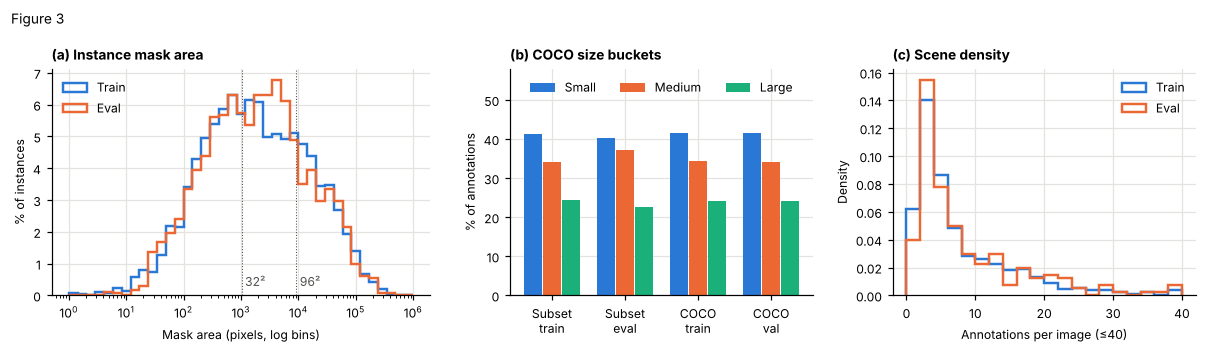

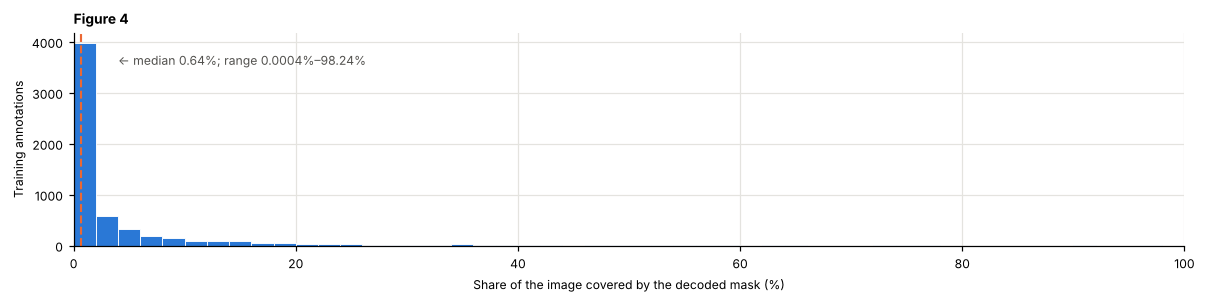

In [8]:
# ---------------------------------------------------------------
# Figure 3: (a) mask area (non-crowd), (b) COCO size buckets vs full COCO, (c) annotations per image
# ---------------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2), gridspec_kw={"width_ratios": [1.25, 1, 1]})
bins = np.logspace(0, 6, 40)
for s, c, lab in [("train", C_TRAIN, "Train"), ("eval", C_EVAL, "Eval")]:
    a = INST[s]["area_px"][INST[s]["crowd"] == 0]
    ax[0].hist(a, bins=bins, histtype="step", lw=1.6, color=c, weights=np.full(len(a), 100 / len(a)), label=lab)
ax[0].set_xscale("log"); ax[0].set_xlabel("Mask area (pixels, log bins)"); ax[0].set_ylabel("% of instances")
for t, l in [(32**2, "32²"), (96**2, "96²")]:
    ax[0].axvline(t, color=INK2, lw=0.7, ls=":"); ax[0].text(t * 1.15, 0.3, l, color=INK2)
ax[0].legend(loc="upper left"); ax[0].set_title("(a) Instance mask area", loc="left")
groups = [size_split_stored(INST["train"]["stored_area"]), size_split_stored(INST["eval"]["stored_area"])]
for s in SPLITS:
    sz = np.array([FULL[s]["sizes"][k] for k in ["small", "medium", "large"]]); groups.append(100 * sz / sz.sum())
groups = np.array(groups); xb = np.arange(4)
for j, (lab, c) in enumerate(zip(["Small", "Medium", "Large"], [C_TRAIN, C_EVAL, C_3])):
    ax[1].bar(xb + (j - 1) * 0.26, groups[:, j], 0.25, color=c, label=lab)
ax[1].set_xticks(xb); ax[1].set_xticklabels(["Subset\ntrain", "Subset\neval", "COCO\ntrain", "COCO\nval"])
ax[1].set_ylabel("% of annotations"); ax[1].set_ylim(0, 58); ax[1].legend(ncol=3, loc="upper center")
ax[1].set_title("(b) COCO size buckets", loc="left")
for s, c, lab in [("train", C_TRAIN, "Train"), ("eval", C_EVAL, "Eval")]:
    pi = Counter(INST[s]["img"]); n = np.array([pi.get(i, 0) for i in cocos[s].imgs])
    ax[2].hist(np.clip(n, 0, 40), bins=np.arange(0, 42, 2), histtype="step", lw=1.6, color=c, density=True, label=lab)
ax[2].set_xlabel("Annotations per image (≤40)"); ax[2].set_ylabel("Density"); ax[2].legend()
ax[2].set_title("(c) Scene density", loc="left")
fig.suptitle("Figure 3", x=0.01, ha="left", fontsize=9); plt.tight_layout(); plt.show()

# ---------------------------------------------------------------
# Figure 4: share of the image covered by each decoded training mask (crowd included, 2% bins)
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.hist(cov, bins=np.arange(0, 102, 2), color=C_TRAIN, edgecolor="white", linewidth=0.6)
ax.axvline(np.median(cov), color=C_EVAL, lw=1.4, ls="--")
ax.text(4, ax.get_ylim()[1] * 0.85, f"← median {np.median(cov):.2f}%; range {cov.min():.4f}%–{cov.max():.2f}%", color=INK2)
ax.set_xlim(0, 100); ax.set_xlabel("Share of the image covered by the decoded mask (%)"); ax.set_ylabel("Training annotations")
ax.set_title("Figure 4", loc="left"); plt.tight_layout(); plt.show()

## 6.4 Image properties and the model's input pipeline
This cell opens **every** image once and records its colour mode, size, colour statistics, brightness, contrast, an MD5 hash (exact duplicates) and a perceptual hash (near-duplicates, used in 6.5). It also checks the official `EfficientSam.preprocess` behaviour: a direct bilinear resize to 1024×1024 **without** aspect-preserving padding.

In [9]:
# ---------------------------------------------------------------
# 6.4a Per-image audit of all 1,000 JPEGs
# ---------------------------------------------------------------
def dhash(im):
    # 64-bit difference hash: similar-looking images get hashes that differ in few bits.
    g = np.asarray(im.convert("L").resize((9, 8)), dtype=np.int16)
    return int("".join("1" if b else "0" for b in (g[:, 1:] > g[:, :-1]).flatten()), 2)

t0 = time.time()
IMG = {}
for s, coco in cocos.items():
    folder = SPLITS[s][1]
    for info in coco.imgs.values():
        p = folder / info["file_name"]
        rec = dict(split=s, exists=p.exists())
        if rec["exists"]:
            raw = p.read_bytes(); rec["md5"] = hashlib.md5(raw).hexdigest()
            try:
                with Image.open(p) as im:
                    im.load()
                    rec.update(mode=im.mode, size=im.size, size_ok=im.size == (info["width"], info["height"]), dhash=dhash(im))
                    a = np.asarray(im.convert("RGB"), dtype=np.float32) / 255.0
                rec["mean"] = a.reshape(-1, 3).mean(0); rec["std"] = a.reshape(-1, 3).std(0)
                rec["mono"] = bool(np.abs(a[..., 0] - a[..., 1]).max() < 0.02 and np.abs(a[..., 1] - a[..., 2]).max() < 0.02)
                g = a.mean(2); rec["lum"] = float(g.mean()); rec["contrast"] = float(g.std())
            except Exception as e:
                rec["error"] = str(e)
        IMG[info["file_name"]] = rec
print(f"audited {len(IMG)} images in {time.time()-t0:.0f}s")

# ---------------------------------------------------------------
# 6.4b Geometry vs the model's square 1024 x 1024 input
# ---------------------------------------------------------------
Wt = np.array([i["width"] for i in cocos["train"].imgs.values()]); Ht = np.array([i["height"] for i in cocos["train"].imgs.values()])
ar = Wt / Ht; stretch = np.maximum(ar, 1 / ar)
print(f"longest side = 640 px for {100*(np.maximum(Wt, Ht) == 640).mean():.1f}% of training images")
print(f"widths {Wt.min()}–{Wt.max()} px, heights {Ht.min()}–{Ht.max()} px (separate ranges, not the same photo)")
print(f"landscape {(Wt > Ht).sum()}, portrait {(Wt < Ht).sum()}, square {(Wt == Ht).sum()}; aspect ratio {ar.min():.2f}–{ar.max():.2f}")
print(f"resize to 1024x1024: median upsampling {np.median(MODEL_SIZE / np.maximum(Wt, Ht)):.1f}x, "
      f"median one-axis stretch {np.median(stretch):.2f}, images stretched > 1.3: {100*(stretch > 1.3).mean():.1f}%")

# ---------------------------------------------------------------
# 6.4c Colour statistics, single-channel files, brightness
# ---------------------------------------------------------------
tr = [v for v in IMG.values() if v["split"] == "train"]
print("train mean RGB", np.round(np.mean([v["mean"] for v in tr], 0), 3), "| ImageNet mean", PIXEL_MEAN.flatten().numpy())
print("train avg per-image std", np.round(np.mean([v["std"] for v in tr], 0), 3), "| ImageNet std ", PIXEL_STD.flatten().numpy())
print("colour modes:", dict(Counter((v["split"], v["mode"]) for v in IMG.values())))
print("single-channel (L) JPEGs:", [k for k, v in IMG.items() if v["mode"] == "L"])
print("stored as RGB but visually monochrome:", sum(1 for v in IMG.values() if v["mono"] and v["mode"] != "L"))
lum = np.array([v["lum"] for v in IMG.values()])
print(f"mean luminance {lum.min():.2f}–{lum.max():.2f}, median {np.median(lum):.2f}, images below 0.15: {(lum < 0.15).sum()}")
DARKEST = min(IMG, key=lambda k: IMG[k]["lum"]); LOWEST_CONTRAST = min(IMG, key=lambda k: IMG[k]["contrast"])
print("darkest:", DARKEST, f"({IMG[DARKEST]['lum']:.2f}) | lowest contrast:", LOWEST_CONTRAST, f"({IMG[LOWEST_CONTRAST]['contrast']:.2f})")

audited 1000 images in 25s
longest side = 640 px for 83.4% of training images
widths 300–640 px, heights 200–640 px (separate ranges, not the same photo)
landscape 582, portrait 183, square 35; aspect ratio 0.52–2.83
resize to 1024x1024: median upsampling 1.6x, median one-axis stretch 1.39, images stretched > 1.3: 89.6%
train mean RGB [0.473 0.449 0.406] | ImageNet mean [0.485 0.456 0.406]
train avg per-image std [0.245 0.24  0.242] | ImageNet std  [0.229 0.224 0.225]
colour modes: {('train', 'RGB'): 797, ('train', 'L'): 3, ('eval', 'RGB'): 200}
single-channel (L) JPEGs: ['000000421195.jpg', '000000011801.jpg', '000000532787.jpg']
stored as RGB but visually monochrome: 31
mean luminance 0.07–0.84, median 0.44, images below 0.15: 7
darkest: 000000020720.jpg (0.07) | lowest contrast: 000000315191.jpg (0.05)


## 6.5 Missing data and anomalies
**Selection of examples.** The photographs in Figs. 5–8 were selected deliberately to illustrate specific challenges and anomalies. They are not a random sample and are not used to estimate how often each challenge occurs. Each figure prints the image source and licence recorded by COCO.

missing files: 0 | unreadable: 0 | size mismatch: 0
exact duplicates (MD5): 0


perceptual-hash candidate pairs (<= 6 bits): [('000000260020.jpg', '000000220764.jpg', 6)] -> inspected visually below
image IDs shared by train and eval: 0
train: 5916 masks decoded, empty: 0
eval: 1642 masks decoded, empty: 0


images without annotations: {'train': 7, 'eval': 1} {'train': ['000000136779.jpg', '000000568863.jpg', '000000441863.jpg', '000000124983.jpg', '000000065916.jpg', '000000287822.jpg', '000000218557.jpg'], 'eval': ['000000064574.jpg']}


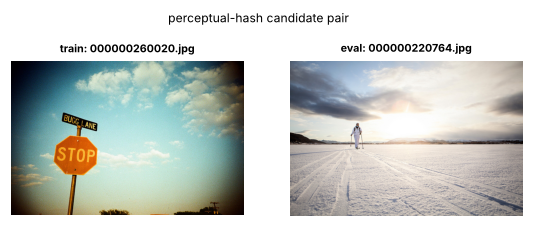

In [10]:
# ---------------------------------------------------------------
# 6.5a Files, duplicates, decoding, images without labels
# ---------------------------------------------------------------
print("missing files:", sum(not v["exists"] for v in IMG.values()),
      "| unreadable:", sum("error" in v for v in IMG.values()),
      "| size mismatch:", sum(not v.get("size_ok", True) for v in IMG.values()))
md5s = Counter(v["md5"] for v in IMG.values()); print("exact duplicates (MD5):", sum(c > 1 for c in md5s.values()))
names = list(IMG); hs = np.array([IMG[k]["dhash"] for k in names], dtype=np.uint64)
pairs = []
for i in range(len(names)):
    d = np.array([bin(int(t)).count("1") for t in np.bitwise_xor(hs[i + 1:], hs[i])])
    pairs += [(names[i], names[i + 1 + j], int(d[j])) for j in np.where(d <= 6)[0]]
print("perceptual-hash candidate pairs (<= 6 bits):", pairs, "-> inspected visually below")
shared = set(cocos["train"].imgs) & set(cocos["eval"].imgs); print("image IDs shared by train and eval:", len(shared))
for s in SPLITS:
    print(f"{s}: {len(INST[s]['ann_id'])} masks decoded, empty: {int((INST[s]['area_px'] == 0).sum())}")
no_ann = {s: [cocos[s].imgs[i]["file_name"] for i in cocos[s].imgs if i not in set(INST[s]["img"])] for s in SPLITS}
print("images without annotations:", {s: len(v) for s, v in no_ann.items()}, no_ann)

def credit(*image_ids):
    # Print the Flickr source and licence that COCO records for each photo shown.
    for iid in image_ids:
        for s, coco in cocos.items():
            if iid in coco.imgs:
                lic = {l["id"]: l["url"] for l in coco.dataset["licenses"]}[coco.imgs[iid]["license"]]
                print(f"  {iid}: {coco.imgs[iid]['flickr_url']}  licence: {lic}")

def show(ax, split, iid, title, ann_ids=None, overlay=True, box=False):
    # Draw a photo, optionally with chosen annotation masks on top.
    coco = cocos[split]; info = coco.imgs[iid]
    im = np.asarray(Image.open(SPLITS[split][1] / info["file_name"]).convert("RGB")) / 255.0
    out = im.copy()
    anns = [a for a in coco.imgToAnns.get(iid, []) if ann_ids is None or a["id"] in ann_ids]
    if overlay:
        pal = plt.cm.tab10(np.arange(10))[:, :3]
        for k, a in enumerate(sorted(anns, key=lambda a: -a["area"])):
            m = decode(a, info["height"], info["width"]); out[m] = 0.45 * out[m] + 0.55 * pal[k % 10]
    ax.imshow(out); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False); ax.set_title(title, fontsize=7.5, loc="left", fontweight="normal")
    if box:
        for a in anns:
            x, y, w, h = a["bbox"]; ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, ec="white", lw=1.2))
            ax.plot(x + w / 2, y + h / 2, "x", color="white", ms=8, mew=2)

# Visual check of the perceptual-hash pair (expected: unrelated images = false positive).
if pairs:
    fig, ax = plt.subplots(1, 2, figsize=(6, 2.4))
    for a, (n, sp) in zip(ax, [(pairs[0][0], IMG[pairs[0][0]]["split"]), (pairs[0][1], IMG[pairs[0][1]]["split"])]):
        a.imshow(Image.open(SPLITS[sp][1] / n)); a.set_title(f"{sp}: {n}", fontsize=7); a.axis("off")
    plt.suptitle("perceptual-hash candidate pair", fontsize=8); plt.show()

In [11]:
# ---------------------------------------------------------------
# 6.5b Selected mask examples, crowd regions, truck, sheep, degenerate and fragmented masks
# ---------------------------------------------------------------
def row(split, ann_id):
    r = INST[split]; return {k: v[int(np.where(r["ann_id"] == ann_id)[0][0])] for k, v in r.items()}

dog, chairs, bike = row("train", 5544), row("train", 906200454495), row("train", 126125)
print(f"dog 5544      : stored {100*dog['stored_area']/(640*480):.2f}% vs decoded {dog['coverage']:.2f}% ({dog['area_px']:,} px); fills {100*dog['box_fill']:.1f}% of its box")
print(f"chair crowd   : stored {chairs['stored_area']:,.0f} px vs decoded {chairs['area_px']:,} px")
print(f"bicycle 126125: {bike['area_px']:,} px = {bike['coverage']:.2f}% of the photo")

for s in SPLITS:
    r = INST[s]; c = r["crowd"] == 1
    mism = (np.abs(r["stored_area"][c] - r["area_px"][c]) / r["area_px"][c] > 0.10).sum()
    print(f"{s}: crowd entries {int(c.sum())} in {len(set(r['img'][c]))} images; stored area off by > 10%: {mism}")

# Truck 397929: rasterise each polygon separately, then the union.
truck = cocos["train"].anns[397929]; tinfo = cocos["train"].imgs[475754]; TH, TW = tinfo["height"], tinfo["width"]
p1, p2 = [mask_utils.decode(r).astype(bool) for r in mask_utils.frPyObjects(truck["segmentation"], TH, TW)]
union = p1 | p2
print(f"\ntruck 397929 in a {TW}x{TH} = {TW*TH:,} px image")
print(f"  stored area (before): {truck['area']:,.2f} px = {100*truck['area']/(TW*TH):.2f}% of the image")
print(f"  polygon 1: {p1.sum():,} px | polygon 2: {p2.sum():,} px | polygon 2 pixels inside polygon 1: {(p1 & p2).sum():,}")
print(f"  sum of polygons: {p1.sum() + p2.sum():,}  <- equals the stored area: overlap counted twice")
print(f"  decoded union (after): {union.sum():,} px = {100*union.sum()/(TW*TH):.2f}%")

sheep = cocos["eval"].anns[1817645]; sinfo = cocos["eval"].imgs[sheep["image_id"]]
su = int(decode(sheep, sinfo["height"], sinfo["width"]).sum())
print(f"\nsheep 1817645 (eval): stored {sheep['area']:,.0f} vs union {su:,} ({100*(sheep['area']/su - 1):+.1f}%)")
bird = cocos["train"].anns[1400800]
print(f"bird 1400800: bbox {bird['bbox']}, polygon {bird['segmentation']}, area {bird['area']:.1f} px")
for s in SPLITS:
    r = INST[s]; nc = r["crowd"] == 0
    print(f"{s}: masks < 4 px: {int((r['area_px'][nc] < 4).sum())} | non-crowd masks with > 1 connected part: {100*(r['n_parts'][nc] > 1).mean():.1f}%")

dog 5544      : stored 46.39% vs decoded 46.41% (142,559 px); fills 58.7% of its box
chair crowd   : stored 2,612 px vs decoded 2,141 px
bicycle 126125: 1,014 px = 0.61% of the photo
train: crowd entries 73 in 66 images; stored area off by > 10%: 31
eval: crowd entries 22 in 20 images; stored area off by > 10%: 8

truck 397929 in a 500x500 = 250,000 px image
  stored area (before): 336,338.72 px = 134.54% of the image
  polygon 1: 241,673 px | polygon 2: 94,666 px | polygon 2 pixels inside polygon 1: 94,666
  sum of polygons: 336,339  <- equals the stored area: overlap counted twice
  decoded union (after): 241,673 px = 96.67%

sheep 1817645 (eval): stored 35,261 vs union 24,160 (+45.9%)
bird 1400800: bbox [214.44, 28.72, 0.95, 3.83], polygon [[215.39, 32.55, 214.44, 28.72, 214.44, 28.72, 214.44, 31.59]], area 1.4 px
train: masks < 4 px: 13 | non-crowd masks with > 1 connected part: 14.9%
eval: masks < 4 px: 0 | non-crowd masks with > 1 connected part: 16.3%


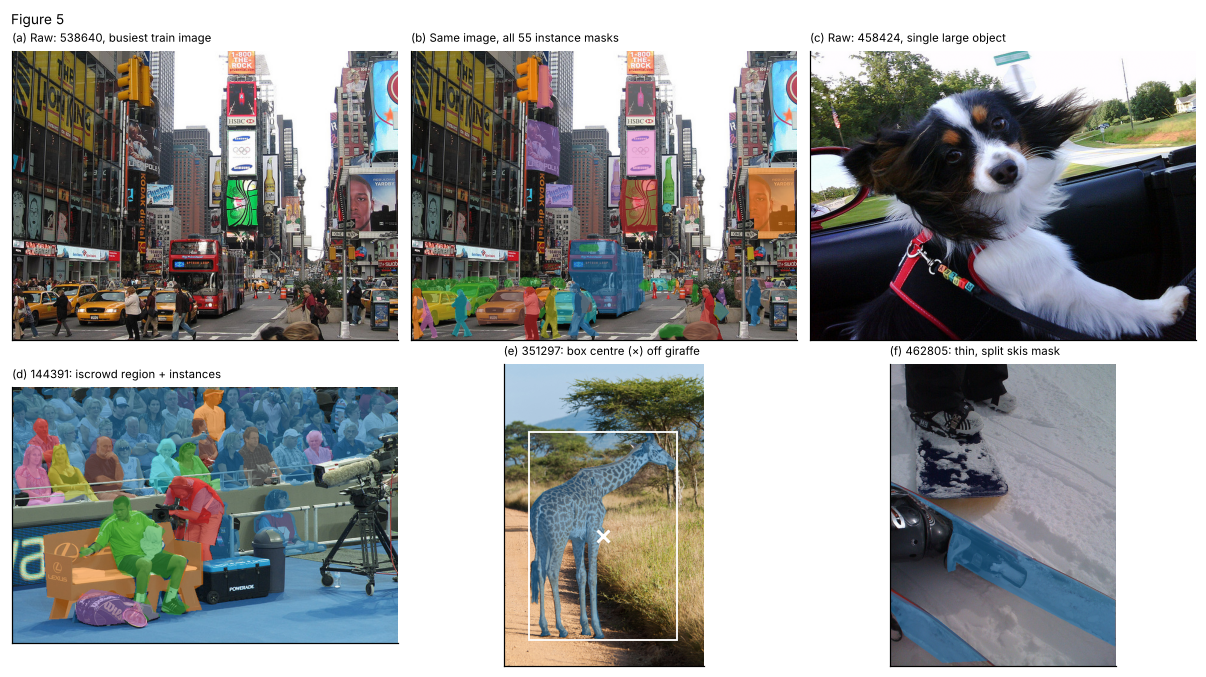

  538640: http://farm3.staticflickr.com/2133/1589723652_147543cef4_z.jpg  licence: http://creativecommons.org/licenses/by-nc-nd/2.0/
  458424: http://farm3.staticflickr.com/2784/4123723564_47ce7cb930_z.jpg  licence: http://creativecommons.org/licenses/by-nc-nd/2.0/
  144391: http://farm4.staticflickr.com/3121/3186591295_d532fab181_z.jpg  licence: http://creativecommons.org/licenses/by-nc-nd/2.0/
  351297: http://farm6.staticflickr.com/5264/5596508487_f28c447b8c_z.jpg  licence: http://creativecommons.org/licenses/by-nc-nd/2.0/
  462805: http://farm4.staticflickr.com/3416/3343979999_895c7f6881_z.jpg  licence: http://creativecommons.org/licenses/by-nc-sa/2.0/


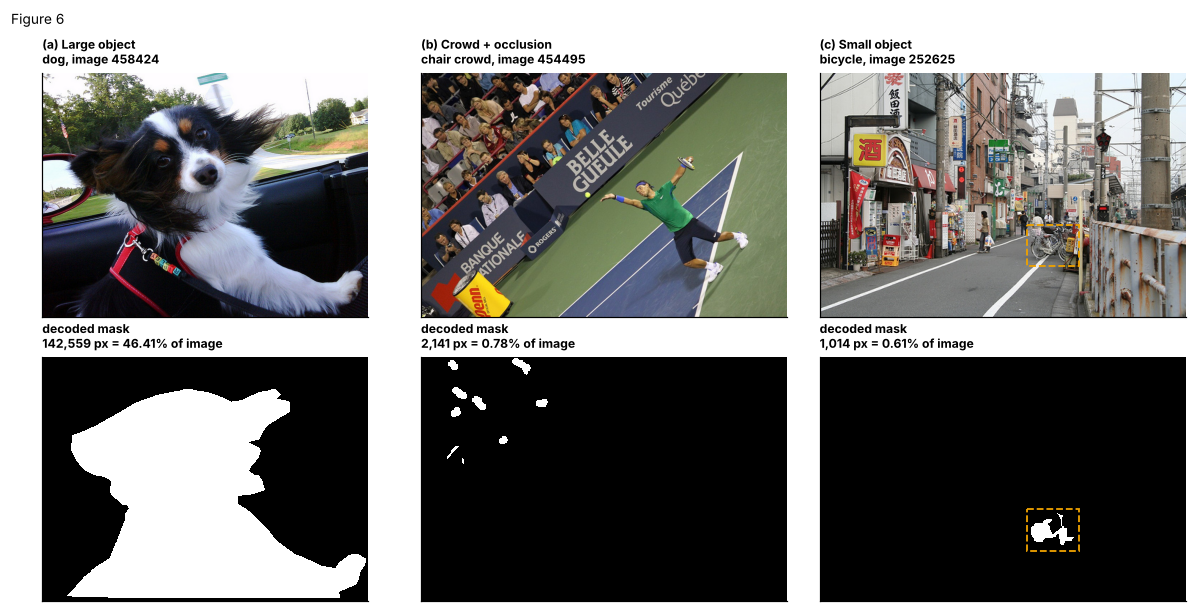

  458424: http://farm3.staticflickr.com/2784/4123723564_47ce7cb930_z.jpg  licence: http://creativecommons.org/licenses/by-nc-nd/2.0/
  454495: http://farm7.staticflickr.com/6184/6082882896_e01b39e1e9_z.jpg  licence: http://creativecommons.org/licenses/by-nc-sa/2.0/
  252625: http://farm1.staticflickr.com/46/188068269_52967f417f_z.jpg  licence: http://creativecommons.org/licenses/by-nc-nd/2.0/


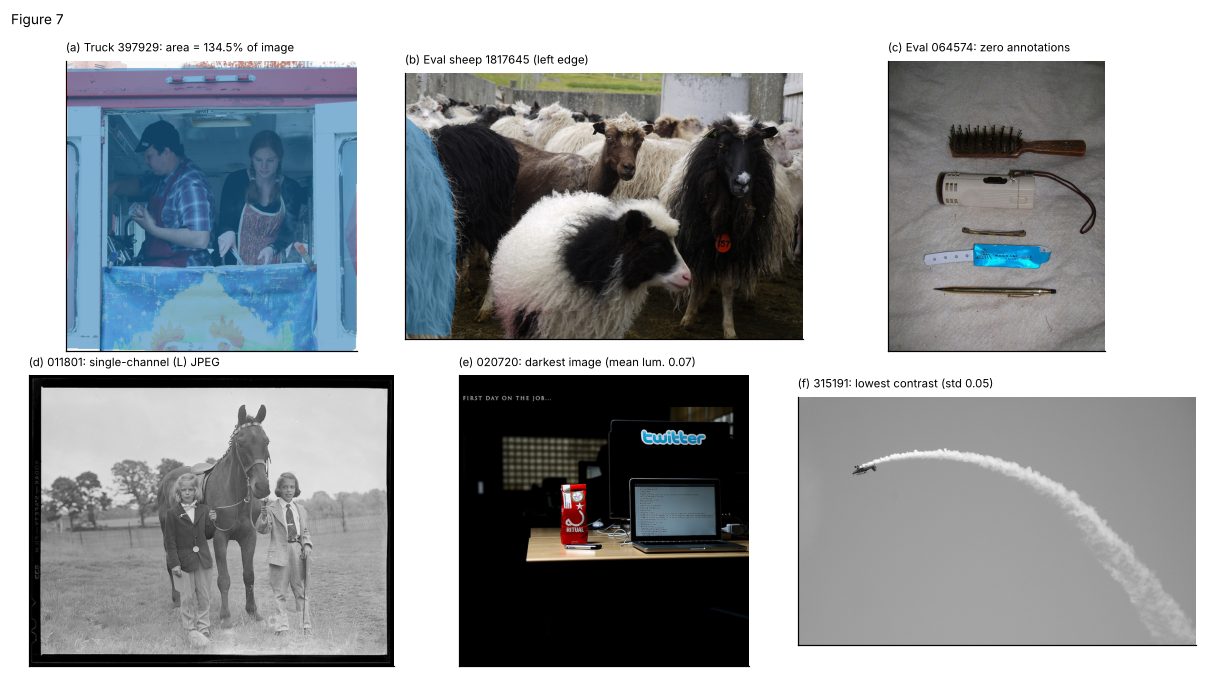

  475754: http://farm3.staticflickr.com/2680/4465762706_ee94b80f00_z.jpg  licence: http://creativecommons.org/licenses/by-nd/2.0/
  360325: http://farm9.staticflickr.com/8012/7569293604_7f0c3a3dbd_z.jpg  licence: http://creativecommons.org/licenses/by-nc-nd/2.0/
  64574: http://farm4.staticflickr.com/3402/3561877308_1393b8b4ce_z.jpg  licence: http://creativecommons.org/licenses/by-nc-nd/2.0/
  11801: http://farm9.staticflickr.com/8518/8380730360_a945c6b5ce_z.jpg  licence: http://creativecommons.org/licenses/by-nc-nd/2.0/
  20720: http://farm4.staticflickr.com/3303/3503590554_5f13eed60c_z.jpg  licence: http://creativecommons.org/licenses/by-nc-nd/2.0/
  315191: http://farm4.staticflickr.com/3725/8928344781_c3e1bc63ab_z.jpg  licence: http://creativecommons.org/licenses/by-nc/2.0/


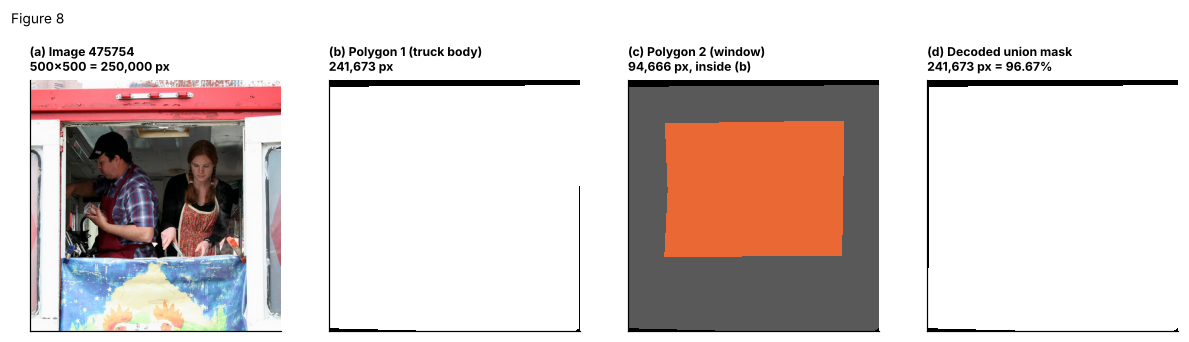

  475754: http://farm3.staticflickr.com/2680/4465762706_ee94b80f00_z.jpg  licence: http://creativecommons.org/licenses/by-nd/2.0/


In [12]:
# ---------------------------------------------------------------
# Figure 5: raw examples from the training subset
# ---------------------------------------------------------------
fig, ax = plt.subplots(2, 3, figsize=(11, 6.2)); ax = ax.ravel()
show(ax[0], "train", 538640, "(a) Raw: 538640, busiest train image", overlay=False)
show(ax[1], "train", 538640, "(b) Same image, all 55 instance masks")
show(ax[2], "train", 458424, "(c) Raw: 458424, single large object", overlay=False)
show(ax[3], "train", 144391, "(d) 144391: iscrowd region + instances")
show(ax[4], "train", 351297, "(e) 351297: box centre (×) off giraffe",
     ann_ids=[a["id"] for a in cocos["train"].imgToAnns[351297] if CAT_NAME[a["category_id"]] == "giraffe"], box=True)
show(ax[5], "train", 462805, "(f) 462805: thin, split skis mask",
     ann_ids=[a["id"] for a in cocos["train"].imgToAnns[462805] if CAT_NAME[a["category_id"]] == "skis"])
fig.suptitle("Figure 5", x=0.01, ha="left", fontsize=9); plt.tight_layout(); plt.show()
credit(538640, 458424, 144391, 351297, 462805)

# ---------------------------------------------------------------
# Figure 6: original photo (top) and decoded mask (bottom), no overlays or cropping
# ---------------------------------------------------------------
fig, ax = plt.subplots(2, 3, figsize=(11, 5.6))
for j, (aid, t) in enumerate([(5544, "(a) Large object\ndog, image 458424"),
                              (906200454495, "(b) Crowd + occlusion\nchair crowd, image 454495"),
                              (126125, "(c) Small object\nbicycle, image 252625")]):
    a = cocos["train"].anns[aid]; info = cocos["train"].imgs[a["image_id"]]
    m = decode(a, info["height"], info["width"])
    ax[0, j].imshow(Image.open(SPLITS["train"][1] / info["file_name"]).convert("RGB")); ax[0, j].set_title(t, fontsize=8, loc="left")
    ax[1, j].imshow(m, cmap="gray", interpolation="nearest")
    ax[1, j].set_title(f"decoded mask\n{int(m.sum()):,} px = {100*m.mean():.2f}% of image", fontsize=8, loc="left")
    if aid == 126125:   # dashed box only to help locate the tiny bicycle
        x, y, w, h = a["bbox"]
        for k in (0, 1): ax[k, j].add_patch(plt.Rectangle((x - 6, y - 6), w + 12, h + 12, fill=False, ec="#eda100", lw=1.2, ls="--"))
    for k in (0, 1): ax[k, j].set_xticks([]); ax[k, j].set_yticks([]); ax[k, j].grid(False)
fig.suptitle("Figure 6", x=0.01, ha="left", fontsize=9); plt.tight_layout(); plt.show()
credit(458424, 454495, 252625)

# ---------------------------------------------------------------
# Figure 7: anomalies and image-quality extremes
# ---------------------------------------------------------------
fig, ax = plt.subplots(2, 3, figsize=(11, 6.2)); ax = ax.ravel()
show(ax[0], "train", 475754, "(a) Truck 397929: area = 134.5% of image", ann_ids=[397929])
show(ax[1], "eval", 360325, "(b) Eval sheep 1817645 (left edge)", ann_ids=[1817645])
show(ax[2], "eval", 64574, "(c) Eval 064574: zero annotations", overlay=False)
show(ax[3], "train", 11801, "(d) 011801: single-channel (L) JPEG", overlay=False)
dk = cocos[IMG[DARKEST]["split"]]; lc = cocos[IMG[LOWEST_CONTRAST]["split"]]
dk_id = next(i for i, v in dk.imgs.items() if v["file_name"] == DARKEST); lc_id = next(i for i, v in lc.imgs.items() if v["file_name"] == LOWEST_CONTRAST)
show(ax[4], IMG[DARKEST]["split"], dk_id, f"(e) {dk_id:06d}: darkest image (mean lum. {IMG[DARKEST]['lum']:.2f})", overlay=False)
show(ax[5], IMG[LOWEST_CONTRAST]["split"], lc_id, f"(f) {lc_id:06d}: lowest contrast (std {IMG[LOWEST_CONTRAST]['contrast']:.2f})", overlay=False)
fig.suptitle("Figure 7", x=0.01, ha="left", fontsize=9); plt.tight_layout(); plt.show()
credit(475754, 360325, 64574, 11801, dk_id, lc_id)

# ---------------------------------------------------------------
# Figure 8: truck annotation 397929 polygon by polygon
# ---------------------------------------------------------------
fig, ax = plt.subplots(1, 4, figsize=(11, 3.1))
ax[0].imshow(Image.open(SPLITS["train"][1] / tinfo["file_name"])); ax[0].set_title(f"(a) Image 475754\n{TW}×{TH} = {TW*TH:,} px", fontsize=8, loc="left")
ax[1].imshow(p1, cmap="gray", interpolation="nearest"); ax[1].set_title(f"(b) Polygon 1 (truck body)\n{p1.sum():,} px", fontsize=8, loc="left")
over = np.zeros((TH, TW, 3)); over[p1] = 0.35; over[p2] = [0.92, 0.41, 0.20]
ax[2].imshow(over, interpolation="nearest"); ax[2].set_title(f"(c) Polygon 2 (window)\n{p2.sum():,} px, inside (b)", fontsize=8, loc="left")
ax[3].imshow(union, cmap="gray", interpolation="nearest"); ax[3].set_title(f"(d) Decoded union mask\n{union.sum():,} px = {100*union.mean():.2f}%", fontsize=8, loc="left")
for a in ax: a.set_xticks([]); a.set_yticks([]); a.grid(False)
fig.suptitle("Figure 8", x=0.01, ha="left", fontsize=9); plt.tight_layout(rect=[0, 0, 1, 0.92]); plt.show()
credit(475754)

## 6.6 Challenges specific to promptable segmentation
How well do simple prompts describe each object? We measure how much of its box each mask fills, and how often the **box centre** misses the object.

train: median box fill 58.6%, fill < 30%: 7.3%, box centre off the mask: 12.5%
eval: median box fill 57.0%, fill < 30%: 8.2%, box centre off the mask: 14.8%
  dining table  box centre off the mask: 27.8%
  suitcase      box centre off the mask: 21.0%
  chair         box centre off the mask: 19.0%
  traffic light box centre off the mask: 2.0%


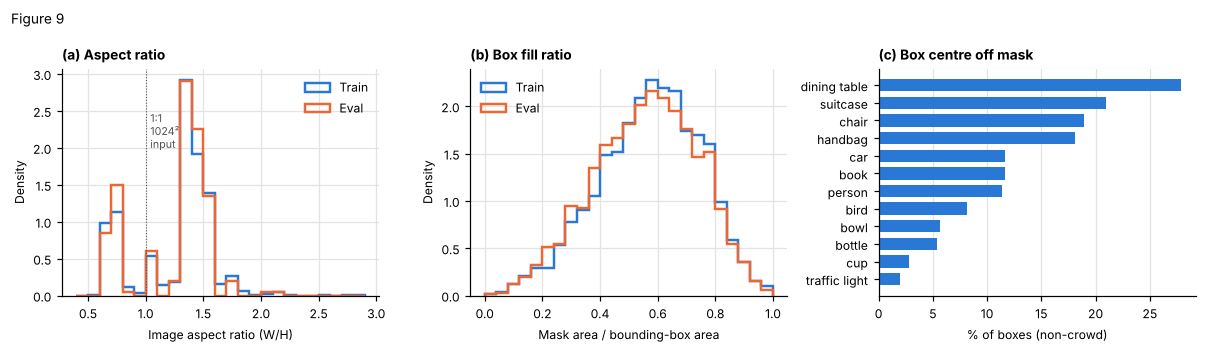

In [13]:
# ---------------------------------------------------------------
# 6.6a Box fill and box-centre misses
# ---------------------------------------------------------------
for s in SPLITS:
    r = INST[s]; nc = r["crowd"] == 0
    print(f"{s}: median box fill {100*np.median(r['box_fill'][nc]):.1f}%, fill < 30%: {100*(r['box_fill'][nc] < 0.3).mean():.1f}%, "
          f"box centre off the mask: {100*(~r['centre_in'][nc]).mean():.1f}%")
r = INST["train"]; nc = r["crowd"] == 0
top12 = order[:12]
miss = {k: 100 * np.mean(~r["centre_in"][nc & (r["cat"] == k)]) for k in top12}
for k in ["dining table", "suitcase", "chair", "traffic light"]:
    print(f"  {k:13s} box centre off the mask: {miss[k]:.1f}%")

# ---------------------------------------------------------------
# Figure 9: (a) aspect ratio, (b) box fill ratio, (c) box centre off the mask by category
# ---------------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
for s, c, lab in [("train", C_TRAIN, "Train"), ("eval", C_EVAL, "Eval")]:
    a = np.array([i["width"] / i["height"] for i in cocos[s].imgs.values()])
    ax[0].hist(a, bins=np.linspace(0.4, 2.9, 26), histtype="step", lw=1.6, color=c, density=True, label=lab)
    f = INST[s]["box_fill"][INST[s]["crowd"] == 0]
    ax[1].hist(f, bins=np.linspace(0, 1, 26), histtype="step", lw=1.6, color=c, density=True, label=lab)
ax[0].axvline(1, color=INK2, lw=0.7, ls=":"); ax[0].text(1.04, 2.0, "1:1\n1024²\ninput", color=INK2, fontsize=7)
ax[0].set_xlabel("Image aspect ratio (W/H)"); ax[0].set_ylabel("Density"); ax[0].legend(); ax[0].set_title("(a) Aspect ratio", loc="left")
ax[1].set_xlabel("Mask area / bounding-box area"); ax[1].set_ylabel("Density"); ax[1].legend(loc="upper left"); ax[1].set_title("(b) Box fill ratio", loc="left")
o = sorted(top12, key=lambda k: miss[k])
ax[2].barh(range(12), [miss[k] for k in o], color=C_TRAIN, height=0.7); ax[2].set_yticks(range(12)); ax[2].set_yticklabels(o)
ax[2].set_xlabel("% of boxes (non-crowd)"); ax[2].grid(axis="y", visible=False); ax[2].set_title("(c) Box centre off mask", loc="left")
fig.suptitle("Figure 9", x=0.01, ha="left", fontsize=9); plt.tight_layout(); plt.show()

## 6.7 Evaluation metrics
The metric functions used in the next milestone are defined here and checked on tiny examples. All scores are computed per **non-crowd** object at the original image resolution and then averaged over objects.

* **IoU** = |M̂ ∩ M| / |M̂ ∪ M| (overlap ÷ area covered by either mask); 1 = perfect, 0 = no overlap. **Object-level averaging**: compute IoU per object, then average, so every object counts equally and large masks cannot dominate.
* **Dice** = 2|M̂ ∩ M| / (|M̂| + |M|), a companion score. It tracks IoU closely, so it is not independent evidence.
* **Pixel accuracy** is **not** used: with a median coverage of 0.64%, an all-background prediction still scores about 99%.
* **Boundary IoU**: IoU computed only within a thin band around each contour, which is sensitive to errors on thin or fragmented objects.
* **Stratification**: by COCO size bucket (recomputed areas) and supercategory, with sample counts. Categories with no eligible eval instance are reported as *unavailable*.
* **COCO mask AP** (pycocotools) applies only to the detector-prompted protocol of the paper. Prompted IoU/Dice are not COCO AP.

In [14]:
# ---------------------------------------------------------------
# 6.7a Metric functions (used in Part B and in the full evaluation)
# ---------------------------------------------------------------
def iou(pred, true):
    inter = np.logical_and(pred, true).sum(); union = np.logical_or(pred, true).sum()
    return inter / union if union else 1.0

def dice(pred, true):
    inter = np.logical_and(pred, true).sum(); total = pred.sum() + true.sum()
    return 2 * inter / total if total else 1.0

def pixel_accuracy(pred, true):
    return (pred == true).mean()

def boundary(mask, d):
    # Pixels of the mask within distance d of its contour (Cheng et al., CVPR 2021).
    return mask & ~ndimage.binary_erosion(mask, iterations=d, border_value=0)

def boundary_iou(pred, true, dilation_ratio=0.02):
    d = max(1, int(round(dilation_ratio * np.hypot(*true.shape))))   # band width = 2% of the image diagonal
    return iou(boundary(pred, d), boundary(true, d))

# Tiny demonstration on a median-sized object (0.64% of a 640x480 image).
H, W = 480, 640; side = int(np.sqrt(0.0064 * H * W))
true = np.zeros((H, W), bool); true[200:200 + side, 300:300 + side] = True
empty = np.zeros_like(true)                                        # "predict background everywhere"
shifted = np.roll(true, 4, axis=1)                                 # a slightly shifted prediction
print(f"object covers {100*true.mean():.2f}% of the image")
print(f"all-background prediction: pixel accuracy = {100*pixel_accuracy(empty, true):.1f}%  but IoU = {iou(empty, true):.2f}, Dice = {dice(empty, true):.2f}")
print(f"shifted by 4 px          : IoU = {iou(shifted, true):.3f}, Dice = {dice(shifted, true):.3f}, Boundary IoU = {boundary_iou(shifted, true):.3f}")

unavailable = [k for k in ALL80 if ((INST["eval"]["cat"] == k) & (INST["eval"]["crowd"] == 0)).sum() == 0]
print("categories reported as 'unavailable' (no eligible eval instance):", unavailable)
print("eligible non-crowd eval instances:", int((INST["eval"]["crowd"] == 0).sum()))

object covers 0.63% of the image
all-background prediction: pixel accuracy = 99.4%  but IoU = 0.00, Dice = 0.00
shifted by 4 px          : IoU = 0.833, Dice = 0.909, Boundary IoU = 0.778
categories reported as 'unavailable' (no eligible eval instance): ['fire hydrant', 'bear', 'snowboard', 'toaster']
eligible non-crowd eval instances: 1620


---
# Part B: Data Loading and Preprocessing Pipeline (report Section 6.8)

### What changed compared with the official repository
The official repo (`yformer/EfficientSAM`) ships **no dataset loader**. Its example notebook reads a single photo with
```python
image_np = np.array(Image.open(img_path)); img_tensor = ToTensor()(image_np)
```
and `EfficientSam.forward()` then resizes (bilinear, straight to 1024×1024) and normalises (ImageNet mean/std) **inside** the model. All code below is ours; each deviation is marked **(CHANGE n)** in the comments:

| # | Official code | Our pipeline | Reason |
|---|---|---|---|
| 1 | `Image.open` as stored | `.convert("RGB")` | 3 single-channel JPEGs (6.4) would crash the 3-channel encoder |
| 2 | resize inside `model.preprocess` | the **same** `F.interpolate` call in the loader | lets photos of different sizes be batched; verified identical in B6 |
| 3 | normalise inside the model | written out, **off** when feeding the official model | normalising twice would corrupt the input |
| 4 | no targets | masks decoded with the COCO API; areas recomputed; crowd and < 4 px removed | stored areas are wrong (truck 134.54%), crowds are groups (6.5) |
| 5 | hand-typed prompts | box corners + deepest-interior click | box centre is off the object for 12.5% of objects (6.6) |
| 6 | single image on GPU | on-demand loading, `num_workers=0`, small batches, ≤ 16 prompts per training photo | our laptops: CPU, 8 GB RAM, Jupyter on Windows |

The six rules of report Section 6.8 map to steps **B1–B5**.

In [15]:
# ---------------------------------------------------------------
# B1. Rule 1: always 3-channel RGB  (CHANGE 1)
# ---------------------------------------------------------------
def load_rgb(path):
    # np.array (not np.asarray) returns a writable copy, which torch.from_numpy needs later.
    with Image.open(path) as im:
        return np.array(im.convert("RGB"))

demo = SPLITS["train"][1] / "000000011801.jpg"
print("official loading :", np.array(Image.open(demo)).shape, "<- 1 channel: the encoder expects 3 and fails")
print("our load_rgb     :", load_rgb(demo).shape)

# ---------------------------------------------------------------
# B2. Rules 3, 4 and 6: clean targets with recomputed areas and tags  (CHANGE 4)
# ---------------------------------------------------------------
MIN_MASK_PIXELS = 4

def size_bucket(area):
    return "small" if area < 32**2 else ("medium" if area < 96**2 else "large")

def clean_objects(coco, img_id, counts=None):
    # Promptable objects of one image: no crowd, no specks, areas from the decoded mask, size + supercategory tags.
    info = coco.imgs[img_id]; h, w = info["height"], info["width"]; out = []
    for ann in coco.imgToAnns.get(img_id, []):
        if ann["iscrowd"]:                                   # rule 4: a crowd is a group, not one object
            if counts is not None: counts["dropped crowd"] += 1
            continue
        m = decode(ann, h, w); area = int(m.sum())           # rule 3: never trust the stored "area"
        if area < MIN_MASK_PIXELS:                           # rule 4: un-promptable specks
            if counts is not None: counts["dropped < 4 px"] += 1
            continue
        if counts is not None: counts["kept"] += 1
        out.append(dict(ann_id=ann["id"], category=CAT_NAME[ann["category_id"]],
                        supercategory=CAT_SUPER[ann["category_id"]], bbox_xywh=ann["bbox"], mask=m,
                        area=area, coverage=100 * area / (h * w), size=size_bucket(area)))   # rule 6: tags
    return out

USABLE = {}
for s, coco in cocos.items():
    c = Counter(); USABLE[s] = [i for i in sorted(coco.imgs) if clean_objects(coco, i, c)]
    c["images skipped (no usable object)"] = len(coco.imgs) - len(USABLE[s])
    print(f"[{s}] usable images = {len(USABLE[s])}  {dict(c)}")
t = [o for o in clean_objects(cocos["train"], 475754) if o["ann_id"] == 397929][0]
print(f"truck 397929 after cleaning: area {t['area']:,} px = {t['coverage']:.2f}% (bucket '{t['size']}')")

official loading : (510, 640) <- 1 channel: the encoder expects 3 and fails
our load_rgb     : (510, 640, 3)


[train] usable images = 793  {'kept': 5830, 'dropped crowd': 73, 'dropped < 4 px': 13, 'images skipped (no usable object)': 7}


[eval] usable images = 199  {'kept': 1620, 'dropped crowd': 22, 'images skipped (no usable object)': 1}
truck 397929 after cleaning: area 241,673 px = 96.67% (bucket 'large')


box-centre click on the object : 5100/5830 = 87.5%
deepest-interior click on it   : 5830/5830 = 100.0%


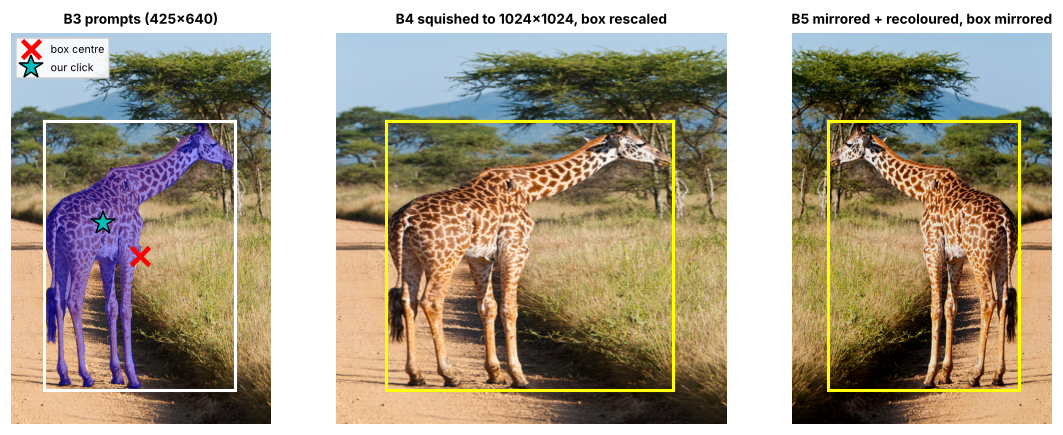

input range [0,1]: 0.00..1.00 | normalised: -2.10..2.64


In [16]:
# ---------------------------------------------------------------
# B3. Rule 5: prompts  (CHANGE 5)
#     EfficientSAM point labels: 1 = foreground click, 2 = box top-left, 3 = box bottom-right, -1 = padding
# ---------------------------------------------------------------
def box_prompt(bbox_xywh):
    x, y, w, h = bbox_xywh
    return np.array([[x, y], [x + w, y + h]], np.float32), np.array([2, 3], np.float32)

def click_prompt(mask):
    # Deepest interior pixel = maximum of the Euclidean distance transform (pad so border objects work).
    dist = ndimage.distance_transform_edt(np.pad(mask, 1))[1:-1, 1:-1]
    y, x = np.unravel_index(np.argmax(dist), dist.shape)
    return np.array([[x + 0.5, y + 0.5], [-1, -1]], np.float32), np.array([1, -1], np.float32)

hit_c = hit_i = n = 0
for i in USABLE["train"]:
    for o in clean_objects(cocos["train"], i):
        m = o["mask"]; H, W = m.shape; x, y, w, h = o["bbox_xywh"]
        hit_c += m[min(int(y + h / 2), H - 1), min(int(x + w / 2), W - 1)]
        p, _ = click_prompt(m); hit_i += m[int(p[0, 1]), int(p[0, 0])]; n += 1
print(f"box-centre click on the object : {hit_c}/{n} = {100*hit_c/n:.1f}%")
print(f"deepest-interior click on it   : {hit_i}/{n} = {100*hit_i/n:.1f}%")

# ---------------------------------------------------------------
# B4. Rule 2: resize to 1024 x 1024 and normalise once  (CHANGES 2 and 3)
# ---------------------------------------------------------------
def to_model_input(img):
    # H x W x 3 uint8 -> 3 x 1024 x 1024 float in [0, 1]; exactly the call inside EfficientSam.preprocess.
    t = torch.from_numpy(img).permute(2, 0, 1).float() / 255.0
    return F.interpolate(t[None], (MODEL_SIZE, MODEL_SIZE), mode="bilinear")[0]

def normalize(x):
    # ImageNet normalisation, identical to EfficientSam.preprocess. NOT used before the official model.
    return (x - PIXEL_MEAN) / PIXEL_STD

def scale_points(points, H, W):
    # The resize is anisotropic, so x and y get different factors; padding (-1) stays -1.
    out = points.copy(); real = out[:, 0] >= 0
    out[real, 0] *= MODEL_SIZE / W; out[real, 1] *= MODEL_SIZE / H
    return out

def to_original(logits_256, H, W):
    # Decoder logits (256 x 256 grid) -> original H x W, then threshold at 0 (as in the official example).
    return F.interpolate(logits_256, (H, W), mode="bicubic") >= 0

# ---------------------------------------------------------------
# B5. Augmentation for the training split only (mirror + colour jitter; image, masks, boxes stay aligned)
# ---------------------------------------------------------------
from torchvision.transforms import ColorJitter
jitter = ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2)

def mirror(img, objects):
    W = img.shape[1]
    return img[:, ::-1].copy(), [{**o, "mask": o["mask"][:, ::-1].copy(),
                                  "bbox_xywh": [W - o["bbox_xywh"][0] - o["bbox_xywh"][2], *o["bbox_xywh"][1:]]} for o in objects]

def recolour(img):
    return jitter(torch.from_numpy(img).permute(2, 0, 1)).permute(1, 2, 0).numpy()

# Visual check on the giraffe (351297): prompts, the 1024 squish and the mirror keep everything aligned.
img = load_rgb(SPLITS["train"][1] / "000000351297.jpg"); H, W = img.shape[:2]
g = [o for o in clean_objects(cocos["train"], 351297) if o["category"] == "giraffe"][0]
bp, _ = box_prompt(g["bbox_xywh"]); cp, _ = click_prompt(g["mask"]); bs = scale_points(bp, H, W)
im_m, (g_m,) = mirror(img, [g]); bm, _ = box_prompt(g_m["bbox_xywh"])
fig, ax = plt.subplots(1, 3, figsize=(11, 4))
ax[0].imshow(img); ax[0].imshow(np.ma.masked_where(~g["mask"], g["mask"]), alpha=0.4, cmap="winter")
ax[0].add_patch(plt.Rectangle(bp[0], *(bp[1] - bp[0]), fill=False, ec="white", lw=2))
ax[0].plot(*(bp[0] + bp[1]) / 2, "rx", ms=12, mew=3, label="box centre"); ax[0].plot(*cp[0], "c*", ms=16, mec="k", label="our click")
ax[0].legend(loc="upper left", fontsize=7, frameon=True, framealpha=0.9); ax[0].set_title(f"B3 prompts ({W}x{H})")
ax[1].imshow(to_model_input(img).permute(1, 2, 0)); ax[1].add_patch(plt.Rectangle(bs[0], *(bs[1] - bs[0]), fill=False, ec="yellow", lw=2))
ax[1].set_title("B4 squished to 1024x1024, box rescaled")
ax[2].imshow(recolour(im_m)); ax[2].add_patch(plt.Rectangle(bm[0], *(bm[1] - bm[0]), fill=False, ec="yellow", lw=2))
ax[2].set_title("B5 mirrored + recoloured, box mirrored")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()
x = to_model_input(img); print(f"input range [0,1]: {x.min():.2f}..{x.max():.2f} | normalised: {normalize(x).min():.2f}..{normalize(x).max():.2f}")

In [17]:
# ---------------------------------------------------------------
# B6. Dataset + DataLoader: one image ON DEMAND (8 GB RAM), batched with padded prompts  (CHANGE 6)
# ---------------------------------------------------------------
MAX_OBJECTS_TRAIN = 16

class CocoPromptDataset(Dataset):
    def __init__(self, split, augment=False, max_objects=None, normalize_image=False):
        self.coco, self.folder, self.ids = cocos[split], SPLITS[split][1], USABLE[split]
        self.augment, self.max_objects, self.normalize_image = augment, max_objects, normalize_image

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        img_id = self.ids[i]; info = self.coco.imgs[img_id]
        img = load_rgb(self.folder / info["file_name"])                 # rule 1
        objs = clean_objects(self.coco, img_id)                         # rules 3, 4, 6
        if self.max_objects and len(objs) > self.max_objects:
            objs = random.sample(objs, self.max_objects)                # memory cap for training
        if self.augment:                                                # training split only
            if random.random() < 0.5: img, objs = mirror(img, objs)
            img = recolour(img)
        H, W = img.shape[:2]
        bp, bl, cp, cl = [], [], [], []
        for o in objs:                                                  # rule 5, then rule 2 scaling
            p, l = box_prompt(o["bbox_xywh"]); bp.append(scale_points(p, H, W)); bl.append(l)
            p, l = click_prompt(o["mask"]);    cp.append(scale_points(p, H, W)); cl.append(l)
        x = to_model_input(img)                                         # rule 2
        if self.normalize_image: x = normalize(x)                       # only for custom models
        return dict(image=x, box_points=torch.tensor(np.stack(bp)), box_labels=torch.tensor(np.stack(bl)),
                    click_points=torch.tensor(np.stack(cp)), click_labels=torch.tensor(np.stack(cl)),
                    true_masks=torch.from_numpy(np.stack([o["mask"] for o in objs])),     # kept at ORIGINAL size
                    info=dict(image_id=img_id, file_name=info["file_name"], original_size=(H, W),
                              categories=[o["category"] for o in objs], supercategories=[o["supercategory"] for o in objs],
                              sizes=[o["size"] for o in objs]))

def collate(batch):
    # Images are stacked; prompts are padded to the largest object count with label -1 (ignored by the model);
    # true masks stay a list because images have different sizes.
    K = max(len(b["box_points"]) for b in batch)
    def pad(t):
        out = torch.full((K, *t.shape[1:]), -1.0); out[: len(t)] = t; return out
    return dict(images=torch.stack([b["image"] for b in batch]),
                **{k: torch.stack([pad(b[k]) for b in batch]) for k in ["box_points", "box_labels", "click_points", "click_labels"]},
                n_objects=torch.tensor([len(b["box_points"]) for b in batch]),
                true_masks=[b["true_masks"] for b in batch], info=[b["info"] for b in batch])

# num_workers=0: worker processes inside Jupyter on Windows need the Dataset in an importable .py file.
train_ds = CocoPromptDataset("train", augment=True, max_objects=MAX_OBJECTS_TRAIN)
eval_ds  = CocoPromptDataset("eval")
train_loader = DataLoader(train_ds, batch_size=4, shuffle=True,  num_workers=0, collate_fn=collate)
eval_loader  = DataLoader(eval_ds,  batch_size=2, shuffle=False, num_workers=0, collate_fn=collate)
print(f"train: {len(train_ds)} images / {len(train_loader)} batches | eval: {len(eval_ds)} images / {len(eval_loader)} batches")

b = next(iter(train_loader))
for k in ["images", "box_points", "box_labels", "click_points", "click_labels", "n_objects"]:
    print(f"  {k:13s} {str(tuple(b[k].shape)):22s} min={b[k].min().item():8.2f} max={b[k].max().item():8.2f}")
print("  true_masks   ", [tuple(m.shape) for m in b["true_masks"]])

# Full pass over every usable image of both splits (no augmentation) to prove the pipeline works end to end.
for name, loader in [("train", DataLoader(CocoPromptDataset("train"), batch_size=4, collate_fn=collate)), ("eval", eval_loader)]:
    t0, n_img, n_obj, bad, sizes = time.time(), 0, 0, 0, Counter()
    for bb in loader:
        n_img += len(bb["info"]); n_obj += int(bb["n_objects"].sum())
        for inf in bb["info"]: sizes.update(inf["sizes"])
        corners = bb["box_points"][bb["box_labels"] >= 0]
        bad += int((corners < -0.01).any() or (corners > MODEL_SIZE + 0.01).any() or torch.isnan(bb["images"]).any())
    print(f"[{name}] images={n_img} objects={n_obj} sizes={dict(sizes)} problems={bad} ({time.time()-t0:.0f}s)")

train: 793 images / 199 batches | eval: 199 images / 100 batches


  images        (4, 3, 1024, 1024)     min=    0.00 max=    1.00
  box_points    (4, 16, 2, 2)          min=   -1.00 max= 1024.00
  box_labels    (4, 16, 2)             min=   -1.00 max=    3.00
  click_points  (4, 16, 2, 2)          min=   -1.00 max=  995.38
  click_labels  (4, 16, 2)             min=   -1.00 max=    1.00
  n_objects     (4,)                   min=    2.00 max=   16.00
  true_masks    [(16, 640, 480), (5, 480, 640), (7, 483, 640), (2, 640, 436)]


[train] images=793 objects=5830 sizes={'medium': 1990, 'large': 1417, 'small': 2423} problems=0 (86s)


[eval] images=199 objects=1620 sizes={'medium': 600, 'small': 660, 'large': 360} problems=0 (24s)


EfficientSAM-Ti: 10.22 M parameters


1) normalize() == model.preprocess(): True


2) identical image embeddings, max |difference| = 0.0


3) 5 eval images, 14 objects, 23s on CPU (smoke test only)
   box   prompts: mean IoU = 0.793, mean Dice = 0.868, mean Boundary IoU = 0.716
   click prompts: mean IoU = 0.477, mean Dice = 0.612, mean Boundary IoU = 0.399


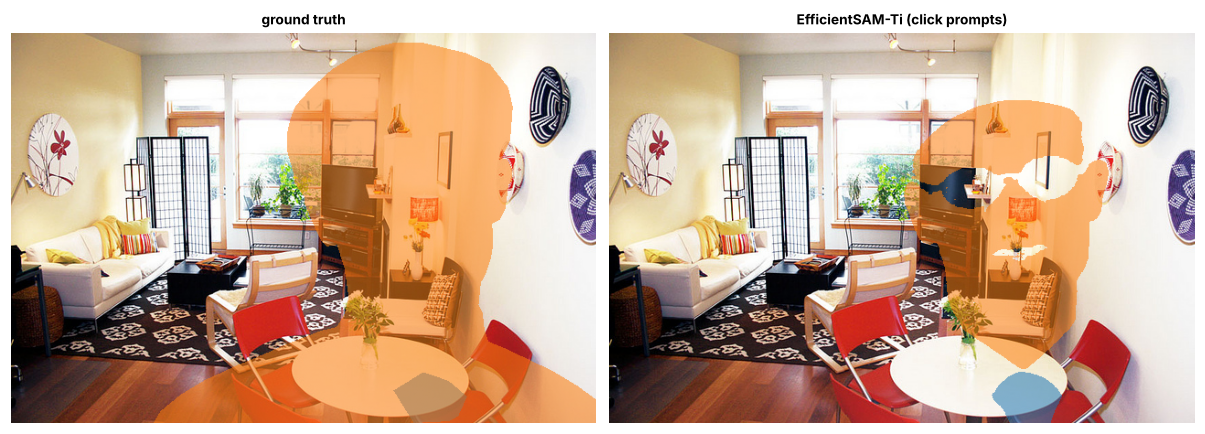

In [18]:
# ---------------------------------------------------------------
# B7. Check against the released EfficientSAM-Ti checkpoint (not a results section)
# ---------------------------------------------------------------
REPO = next((p for p in [Path.cwd(), *Path.cwd().parents[:3]] if (p / "efficient_sam").is_dir()), None)
assert REPO is not None, "Place this notebook inside the EfficientSAM repo (e.g. notebooks/)."
sys.path.insert(0, str(REPO))
from efficient_sam.efficient_sam import build_efficient_sam
# The repo's build_efficient_sam_vitt() uses a path relative to the repo root; we pass an absolute one.
model = build_efficient_sam(encoder_patch_embed_dim=192, encoder_num_heads=3,
                            checkpoint=str(REPO / "weights" / "efficient_sam_vitt.pt")).eval()
print(f"EfficientSAM-Ti: {sum(p.numel() for p in model.parameters())/1e6:.2f} M parameters")

# (1) our normalise() is the model's own preprocessing
x = eval_ds[0]["image"][None]
print("1) normalize() == model.preprocess():", torch.allclose(normalize(x[0])[None], model.preprocess(x), atol=1e-6))
# (2) official path (original-size image, model resizes) and our path (loader resizes) give identical embeddings
info = cocos["eval"].imgs[eval_ds.ids[0]]
orig = torch.from_numpy(load_rgb(SPLITS["eval"][1] / info["file_name"])).permute(2, 0, 1).float()[None] / 255
with torch.no_grad():
    diff = (model.get_image_embeddings(orig) - model.get_image_embeddings(x)).abs().max().item()
print("2) identical image embeddings, max |difference| =", diff)

# (3) smoke test on 5 eval images with the 6.7 metrics
res = {m: defaultdict(list) for m in ["box", "click"]}; t0 = time.time()
for n, bb in enumerate(DataLoader(eval_ds, batch_size=1, collate_fn=collate)):
    if n == 5: break
    H, W = bb["info"][0]["original_size"]; k = int(bb["n_objects"][0]); true = bb["true_masks"][0].numpy()
    with torch.no_grad():
        emb = model.get_image_embeddings(bb["images"])                       # encoder: once per image
        for mode in res:                                                     # decoder: once per prompt type
            logits, iou_pred = model.predict_masks(emb, bb[f"{mode}_points"], bb[f"{mode}_labels"], multimask_output=True,
                                                   input_h=MODEL_SIZE, input_w=MODEL_SIZE)
            best = iou_pred.argmax(-1)                                       # keep the model's most confident of 3 masks
            logits = torch.take_along_dim(logits, best[..., None, None, None], dim=2)[:, :, 0]
            pred = to_original(logits[0, :k][None], H, W)[0].numpy()
            for p_, t_ in zip(pred, true):
                res[mode]["IoU"].append(iou(p_, t_)); res[mode]["Dice"].append(dice(p_, t_)); res[mode]["Boundary IoU"].append(boundary_iou(p_, t_))
print(f"3) 5 eval images, {len(res['box']['IoU'])} objects, {time.time()-t0:.0f}s on CPU (smoke test only)")
for mode, d in res.items():
    print(f"   {mode:5s} prompts: " + ", ".join(f"mean {k} = {np.mean(v):.3f}" for k, v in d.items()))

img_e = load_rgb(SPLITS["eval"][1] / bb["info"][0]["file_name"])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, masks, t in [(ax[0], true, "ground truth"), (ax[1], pred, "EfficientSAM-Ti (click prompts)")]:
    a.imshow(img_e); a.axis("off"); a.set_title(t)
    for i, m in enumerate(masks): a.imshow(np.ma.masked_where(~m, np.full(m.shape, i % 10)), cmap="tab10", vmin=0, vmax=9, alpha=0.55)
plt.tight_layout(); plt.show()

## Summary
**Part A (EDA)** recomputes everything in report Section 6 from the real files: Table 2, the category imbalance (Figs. 1–2), object scale and coverage (Figs. 3–4), image properties, the anomalies including the truck's per-polygon areas (Figs. 5–8), the prompt challenges (Fig. 9), and the metric definitions (IoU, Dice, pixel accuracy, Boundary IoU, unavailable categories, COCO AP scope).

**Part B (preprocessing)** implements the six rules of Section 6.8:
1. 3-channel RGB;
2. the official 1024×1024 bilinear resize with prompts rescaled, normalisation applied once, original size kept;
3. targets from decoded masks with recomputed areas;
4. crowd entries and masks under 4 px removed, empty images skipped;
5. box and deepest-interior click prompts;
6. size and supercategory tags.

It wraps them in an on-demand `Dataset`/`DataLoader` that fits 8 GB RAM, runs over every image without errors, and is verified against the released EfficientSAM-Ti model (identical normalisation and embeddings).

**Next milestone:** full evaluation of EfficientSAM-Ti/S, SAM and MobileSAM on the 200 eval images with these loaders and the 6.7 metrics.